# Lung simulation fidelity
Redraw the learned-distribution comparison from saved samples and metrics. Run with the `lightning` kernel. After computing UMAP once, rerun only the plotting and saving cells to tune the figure.

In [23]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scdeepsim").is_dir())
RESULTS = PROJECT_ROOT / "experiments/outputs/simulation_fidelity/unified-20260915-formal/nodes/lung/aggregate/official"
OUTPUT = PROJECT_ROOT / "experiments/outputs/lung_simulation_fidelity_preview.png"

COLORS = {
    "real": "#4c566a",
    "scdeepsim": "#0072b2",
    "scdiffusion": "#cc79a7",
    "scvi_prior": "#009e73",
    "scdesign3": "#d55e00",
}
FIGSIZE = (15, 8.8)
UMAP_POINT_SIZE, UMAP_ALPHA = 5, 0.65
GENE_POINT_SIZE, GENE_ALPHA = 8, 0.4


## Saved results

In [2]:
config = json.loads((RESULTS / "learned_distribution_baseline_metadata.json").read_text())["config"]
metrics = pd.read_csv(RESULTS / "learned_distribution_metrics.csv")
methods = config["methods"]
keys = ["real", *methods]
names = metrics.set_index("method_key")["method"].to_dict()
with np.load(RESULTS / "_aggregate_work/merged_samples.npz") as archive:
    samples = {key: archive[key] for key in keys}

seed = config["seed"]
max_cells = config["eval"]["umap_max_cells_per_method"]
n_neighbors = config["eval"]["umap_n_neighbors"]
min_dist = config["eval"]["umap_min_dist"]
dpi = config["figure"]["dpi"]
title = config["figure"]["title"]
means = {key: x.mean(axis=0) for key, x in samples.items()}
variances = {key: x.var(axis=0) for key, x in samples.items()}

## Joint UMAP
Subsampling follows the original method order and per-method seed offsets. The coordinates remain in memory for subsequent plotting edits.

In [3]:
subsets = []
for offset, key in enumerate(keys):
    x = samples[key]
    if max_cells is not None and len(x) > max_cells:
        indices = np.random.default_rng(seed + offset).choice(len(x), max_cells, replace=False)
        x = x[indices]
    subsets.append(x)

embedding = umap.UMAP(
    n_neighbors=n_neighbors,
    min_dist=min_dist,
    metric="euclidean",
    random_state=seed,
    n_components=2,
).fit_transform(np.vstack(subsets))
embeddings = dict(zip(keys, np.split(embedding, np.cumsum([len(x) for x in subsets])[:-1])))

/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Figure
Edit this cell to tune the panels without recomputing UMAP.

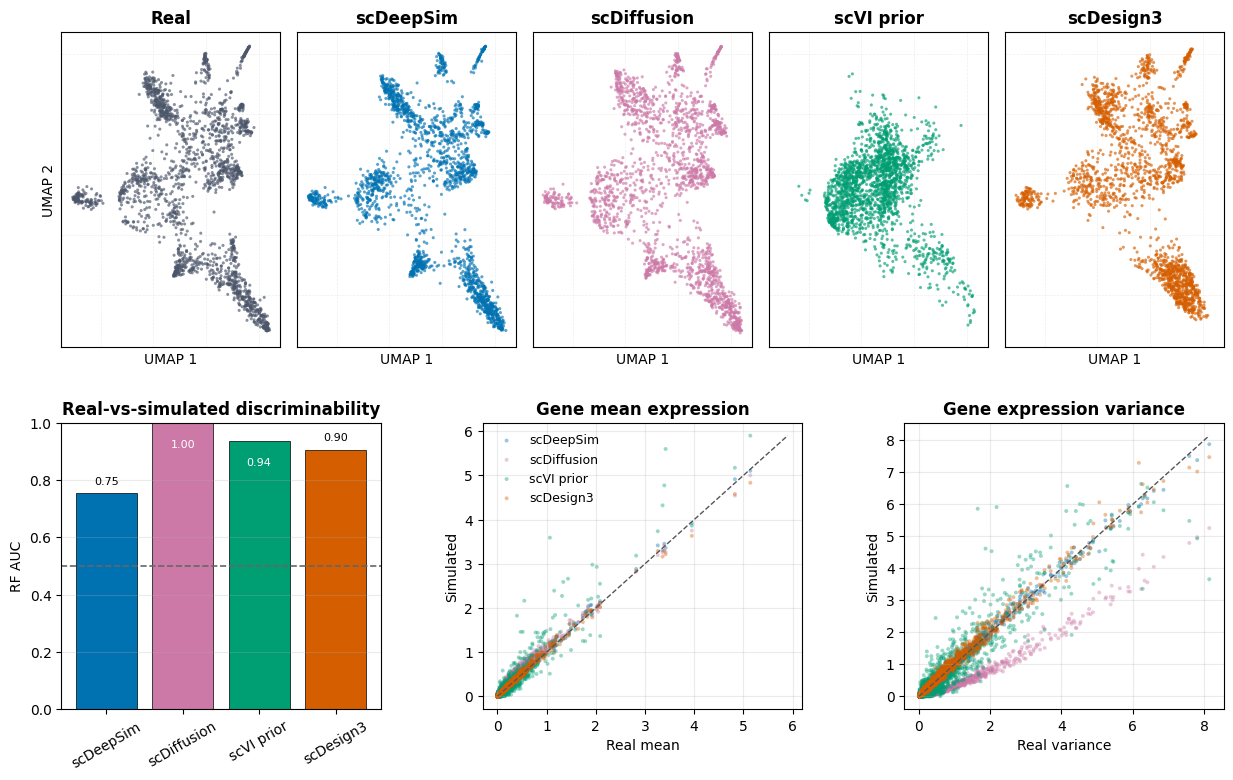

In [24]:
plt.close("all")
fig = plt.figure(figsize=FIGSIZE)
outer = fig.add_gridspec(2, 1, height_ratios=[1.1, 1.0], hspace=0.25)
top = outer[0].subgridspec(1, len(keys), wspace=0.08)
bottom = outer[1].subgridspec(1, 3, wspace=0.32)

lower, upper = embedding.min(axis=0), embedding.max(axis=0)
pad = (upper - lower) * 0.05
umap_axes = []
for i, key in enumerate(keys):
    ax = fig.add_subplot(top[0, i])
    xy = embeddings[key]
    ax.scatter(xy[:, 0], xy[:, 1], s=UMAP_POINT_SIZE, alpha=UMAP_ALPHA,
               edgecolors="none", color=COLORS[key])
    ax.set_title(names[key], fontweight="bold")
    ax.set_xlabel("UMAP 1")
    ax.set_xlim(lower[0] - pad[0], upper[0] + pad[0])
    ax.set_ylim(lower[1] - pad[1], upper[1] + pad[1])
    ax.grid(alpha=0.2, linestyle="--", linewidth=0.5)
    ax.tick_params(axis="both", which="both", bottom=False, top=False,
                   left=False, right=False, labelbottom=False, labelleft=False)
    umap_axes.append(ax)
umap_axes[0].set_ylabel("UMAP 2")

ax_auc = fig.add_subplot(bottom[0, 0])
ax_mean = fig.add_subplot(bottom[0, 1])
ax_var = fig.add_subplot(bottom[0, 2])
data = metrics.set_index("method_key").loc[methods]
bars = ax_auc.bar(data["method"], data["auc"], color=[COLORS[k] for k in methods],
                  edgecolor="black", linewidth=0.5)
ax_auc.axhline(0.5, color="#666666", linestyle="--", linewidth=1.2)
ax_auc.set_ylim(0, 1)
ax_auc.set_ylabel("RF AUC")
ax_auc.set_title("Real-vs-simulated discriminability", fontweight="bold")
ax_auc.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, data["auc"]):
    inside = value > 0.92
    ax_auc.text(bar.get_x() + bar.get_width() / 2,
                value - 0.06 if inside else value + 0.025, f"{value:.2f}",
                ha="center", va="top" if inside else "bottom", fontsize=8,
                color="white" if inside else "black")
ax_auc.tick_params(axis="x", rotation=30)

for ax, stats, panel_title, xlabel in [
    (ax_mean, means, "Gene mean expression", "Real mean"),
    (ax_var, variances, "Gene expression variance", "Real variance"),
]:
    for key in methods:
        ax.scatter(stats["real"], stats[key], s=GENE_POINT_SIZE, alpha=GENE_ALPHA,
                   edgecolors="none", color=COLORS[key], label=names[key])
    lo = min(float(values.min()) for values in stats.values())
    hi = max(float(values.max()) for values in stats.values())
    ax.plot([lo, hi], [lo, hi], color="#555555", linestyle="--", linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Simulated")
    ax.set_title(panel_title, fontweight="bold")
    ax.grid(alpha=0.25)
ax_mean.legend(frameon=False, fontsize=9, loc="best")
# fig.suptitle(title, fontsize=15, fontweight="bold", y=1.02)
plt.show()

## Save

In [25]:
fig.savefig(OUTPUT, dpi=dpi, bbox_inches="tight")
OUTPUT

PosixPath('/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/experiments/outputs/lung_simulation_fidelity_preview.png')